<a href="https://colab.research.google.com/github/jsmak/dl-framework/blob/main/05_autograd/01_autograd_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 자동미분(Autograd)과 계산 그래프 만들기

4강에서는 PyTorch의 `loss.backward()` 한 줄이 기울기를 모두 계산해 주었습니다.
이번에는 **같은 섭씨(°C) → 화씨(°F) 문제**를 PyTorch 없이 NumPy만으로 풀면서, `backward()` 안에서 무슨 일이 일어나는지 직접 만들어 봅니다.

핵심 아이디어는 **계산 그래프**입니다.
순전파를 할 때 "어떤 함수가 어떤 값을 만들었는지"를 기록해 두고, 역전파 때 그 기록을 거꾸로 따라가며 기울기를 전달합니다.

```
순전파 →   X ──[Linear]──▶ ŷ ──[MSE]──▶ L
역전파 ←   X ◀──[Linear]── ŷ ◀──[MSE]── L      (W, b의 기울기는 Linear에서 계산)
```

## **1. 라이브러리 임포트**

PyTorch는 3번에서 결과를 비교할 때만 사용하고, 나머지는 NumPy와 시각화를 위한 matplotlib만으로 `backward()`를 직접 만들어 봅니다.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

## **2. 계산 그래프의 재료: Variable과 Function**

| 클래스 | 하는 일 |
|:---|:---|
| `Variable` | 값(`data`)과 기울기(`grad`), 그리고 **자신을 만든 함수(`creator`)** 를 기억하는 상자 |
| `Function` | 입력 Variable을 받아 출력 Variable을 만들고, 출력에 "내가 만들었다"는 표시(`creator`)를 남김 |


순전파를 하면 `Variable → Function → Variable → Function → …` 이 연결되어 **계산 그래프**가 저절로 만들어집니다.  

`backward()`는 이 연결을 출력에서 입력 쪽으로 거꾸로 따라가며, 각 함수의 `backward`를 호출해 기울기를 앞으로 넘깁니다.   
4강에서 본 **기울기 릴레이(연쇄법칙)** 가 바로 이것입니다.

In [4]:
class Variable:
    def __init__(self, data):
        self.data = data      # 값
        self.grad = None      # 기울기 (역전파 때 채워짐)
        self.creator = None   # 이 값을 만든 함수

    def set_creator(self, func):
        self.creator = func

    def backward(self):
        # 출발점(손실)의 기울기는 1
        if self.grad is None:
            self.grad = np.ones_like(self.data)

        # 계산 그래프를 출력 → 입력 방향으로 거꾸로 따라감
        funcs = [self.creator]
        while funcs:
            f = funcs.pop()
            x, y = f.input, f.output
            x.grad = f.backward(y.grad)       # 뒤에서 받은 기울기로 내 입력의 기울기 계산
            if x.creator is not None:
                funcs.append(x.creator)       # 앞쪽 함수로 계속


class Function:
    def __call__(self, input):
        x = input.data
        y = self.forward(x)          # 실제 계산은 자식 클래스가 담당
        output = Variable(y)
        output.set_creator(self)     # 출력에 "내가 만들었다" 기록 → 그래프 연결
        self.input = input
        self.output = output
        return output

    def forward(self, x):
        raise NotImplementedError()

    def backward(self, gy):
        raise NotImplementedError()

## **3. 첫 번째 함수: x² 미분하기**

**(1) 파이토치 x²**  
먼저 PyTorch로 아주 간단한 함수 f(x) = x²을 미분해보고 넘파이 스퀘어함수를 만들어 결과를 비교해보겠습니다.  

`requires_grad=True`는 "이 값의 기울기를 추적해 달라"는 표시입니다.  

f(x) = x²을 미분하면 2x이므로, x = 5에서의 기울기는 **10**이 나와야 합니다.
(참고: [PyTorch Autograd 튜토리얼](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html))


In [6]:
x = torch.tensor(5.0, requires_grad=True)
f = x ** 2
f.backward()
print(x.grad.item())

10.0


**(2) 넘파이 x²**

이제 numpy로 같은 코드를 구현해보겠습니다.

`Function`을 상속받아 제곱 함수 `Square`를 만듭니다.

| | 계산 |
|:---|:---|
| 순전파 | y = x² |
| 역전파 | x의 기울기 = 2x × gy (gy: 뒤에서 받은 기울기) |

(1)의 PyTorch 코드와 같은 x = 5에서 `backward()`를 부르면, 똑같이 **10**이 나와야 합니다.

In [5]:
class Square(Function):
    def forward(self, x):
        return x ** 2

    def backward(self, gy):
        x = self.input.data
        return 2 * x * gy


x = Variable(np.array(5.0))
f = Square()
y = f(x)          # 순전파: y = 25, y.creator = Square

y.backward()      # 역전파: y.grad = 1에서 출발
print(x.grad)

10.0


## **4. 데이터 준비**

이제 4강의 섭씨(°C) → 화씨(°F) 문제를 같은 방식으로 풀어 봅니다.
4강과 같은 데이터입니다. 입력 X는 섭씨 온도, 정답 y는 화씨 온도입니다.
배열의 크기는 (2, 1)입니다. 행은 데이터의 개수, 열은 입력값의 개수입니다.

In [7]:
# 입력 X: 섭씨 온도
X = np.array([[10.0], [37.78]])

# 정답 y: 화씨 온도
y = np.array([[50.0], [100.0]])

print(X.shape, y.shape)

(2, 1) (2, 1)


## **5. 함수 만들기: Linear와 MeanSquaredError**

각 함수는 **순전파(forward)** 와 **역전파(backward)** 를 한 쌍으로 가집니다.
backward는 "뒤에서 받은 기울기 `gy`"에 "내 층의 기울기"를 곱해 앞으로 넘깁니다.

| 함수 | 순전파 | 역전파 |
|:---|:---|:---|
| `Linear` | ŷ = X · W + b | W의 기울기 = Xᵀ · gy, b의 기울기 = gy의 합, 입력의 기울기 = gy · Wᵀ |
| `MeanSquaredError` | L = 평균((ŷ − y)²) | ŷ의 기울기 = 2/N × (ŷ − y) × gy |

4강의 `nn.Linear`, `nn.MSELoss`가 내부에서 하는 일을 직접 쓴 것입니다.

In [8]:
class Linear(Function):
    def __init__(self, W, b):
        self.W = W
        self.b = b

    def forward(self, x):
        return np.dot(x, self.W.data) + self.b.data

    def backward(self, gy):
        x = self.input.data
        self.W.grad = np.dot(x.T, gy)       # W의 기울기
        self.b.grad = np.sum(gy, axis=0)    # b의 기울기
        return np.dot(gy, self.W.data.T)    # 입력 쪽으로 넘길 기울기


class MeanSquaredError(Function):
    def __init__(self, y_true):
        self.y_true = y_true                # 정답

    def forward(self, x):
        return np.mean((x - self.y_true) ** 2)

    def backward(self, gy):
        x = self.input.data
        n = x.shape[0]                      # 데이터 개수
        return (2.0 / n) * (x - self.y_true) * gy

## **6. 모델, 손실 함수, 학습률 정의**

| 4강 (PyTorch) | 5강 (NumPy로 직접) |
|:---|:---|
| `nn.Linear(1, 1)` | `Linear(W, b)` |
| `nn.MSELoss()` | `MeanSquaredError(y)` |
| `optim.SGD(lr=0.001)` | `lr = 0.001` + 직접 업데이트 |

4강과 결과를 비교하기 위해, w와 b의 초깃값을 4강의 초깃값(w 0.7645, b 0.8300)과 같게 둡니다.

In [9]:
# 파라미터: 4강과 같은 초깃값
W = Variable(np.array([[0.7645]]))
b = Variable(np.array([0.8300]))

# 모델과 손실 함수
model = Linear(W, b)
loss_fn = MeanSquaredError(y)

# 학습률
lr = 0.001

# 입력을 Variable로 감싸기
x = Variable(X)

init_w = W.data[0, 0]
init_b = b.data[0]
print(f"초깃값  w: {init_w:.4f}, b: {init_b:.4f}")

초깃값  w: 0.7645, b: 0.8300


## **7. 계산 그래프 한 번 따라가 보기**

학습에 들어가기 전에, 순전파를 한 번 하고 만들어진 계산 그래프를 확인해 봅니다.  
손실 `loss`에서 `creator`를 따라가면 MeanSquaredError → Linear → 입력 X 순서로 연결되어 있습니다.  
그다음 `backward()`를 부르면 이 연결을 거꾸로 따라가며 W와 b의 기울기가 채워집니다.

In [10]:
# 순전파 한 번
outputs = model(x)
loss = loss_fn(outputs)

# 계산 그래프 확인: loss에서 거꾸로 따라가기
print("loss를 만든 함수    :", type(loss.creator).__name__)
print("그 함수의 입력(ŷ)을 만든 함수:", type(loss.creator.input.creator).__name__)
print("맨 앞 입력 X를 만든 함수 :", x.creator, "← 그래프의 시작점")

# 역전파 한 번
loss.backward()
print(f"\nloss: {loss.data:.4f}")
print(f"w의 기울기: {W.grad[0, 0]:.4f}, b의 기울기: {b.grad[0]:.4f}")

loss를 만든 함수    : MeanSquaredError
그 함수의 입력(ŷ)을 만든 함수: Linear
맨 앞 입력 X를 만든 함수 : None ← 그래프의 시작점

loss: 3332.3074
w의 기울기: -3070.7000, b의 기울기: -111.8122


## **8. 학습: 4단계 반복**

4강의 학습 반복문과 한 줄씩 대응됩니다.   
달라진 점은 `zero_grad()`와 `step()`을 **직접** 한다는 것뿐입니다.  

| 단계 | 4강 (PyTorch) | 5강 (NumPy로 직접) |
|:---|:---|:---|
| 0. 기울기 초기화 | `optimizer.zero_grad()` | `W.grad = None`, `b.grad = None` |
| 1. 순전파 | `model(X)` | `model(x)` |
| 2. 손실 계산 | `loss_fn(outputs, y)` | `loss_fn(outputs)` |
| 3. 역전파 | `loss.backward()` | `loss.backward()` ← 위에서 직접 만든 것 |
| 4. 경사하강법 | `optimizer.step()` | `W.data -= lr * W.grad` |

In [11]:
epochs = 10000
snapshot_epochs = [1, 2, 3, 10, 500, 1000, 2000, 5000, 10000]

losses = []                          # 에폭별 손실 기록
snapshots = [(0, init_w, init_b)]    # 시각화용 (에폭, w, b) 기록

for epoch in range(1, epochs + 1):
    # 0. 기울기 초기화
    W.grad = None
    b.grad = None

    # 1. 순전파: 예측값 계산
    outputs = model(x)

    # 2. 손실 계산
    loss = loss_fn(outputs)

    # 3. 역전파: 기울기 계산
    loss.backward()

    # 4. 경사하강법: w, b 업데이트 (W_new = W_old - 학습률 * 기울기)
    W.data -= lr * W.grad
    b.data -= lr * b.grad

    losses.append(loss.data)

    # 정해 둔 에폭마다 w, b 기록
    if epoch in snapshot_epochs:
        w_now = W.data[0, 0]
        b_now = b.data[0]
        snapshots.append((epoch, w_now, b_now))
        print(f"Epoch {epoch:5d} | loss: {loss.data:10.4f} | w: {w_now:.4f}, b: {b_now:.4f}")

Epoch     1 | loss:  3332.3074 | w: 3.8352, b: 0.9418
Epoch     2 | loss:  1107.7655 | w: 2.2106, b: 0.9067
Epoch     3 | loss:   485.4851 | w: 3.0690, b: 0.9492
Epoch    10 | loss:   242.3111 | w: 2.7650, b: 1.0494
Epoch   500 | loss:   147.7134 | w: 2.5562, b: 7.8335
Epoch  1000 | loss:    89.1536 | w: 2.3874, b: 13.2256
Epoch  2000 | loss:    32.4771 | w: 2.1545, b: 20.6691
Epoch  5000 | loss:     1.5700 | w: 1.8778, b: 29.5099
Epoch 10000 | loss:     0.0101 | w: 1.8061, b: 31.8019


## **9. 학습 결과 확인**

학습 전과 후의 식을 실제 공식과 비교합니다.  
4강(PyTorch)의 결과 **F = 1.8061 × C + 31.8019** 와 같은 값이 나오면, 우리가 만든 `backward()`가 PyTorch와 같은 기울기를 계산했다는 뜻입니다.

In [12]:
final_w = W.data[0, 0]
final_b = b.data[0]

print(f"실제 공식   F = 1.8000 * C + 32.0000")
print(f"학습 전     F = {init_w:.4f} * C + {init_b:.4f}")
print(f"학습 후     F = {final_w:.4f} * C + {final_b:.4f}")

실제 공식   F = 1.8000 * C + 32.0000
학습 전     F = 0.7645 * C + 0.8300
학습 후     F = 1.8061 * C + 31.8019


## **10. 학습 과정 시각화**

4강과 같은 그래프입니다.   
에폭에 따라 예측선(주황 점선)이 실제 공식(검은 실선)에 가까워지는 모습과, 손실이 줄어드는 모습을 확인합니다.

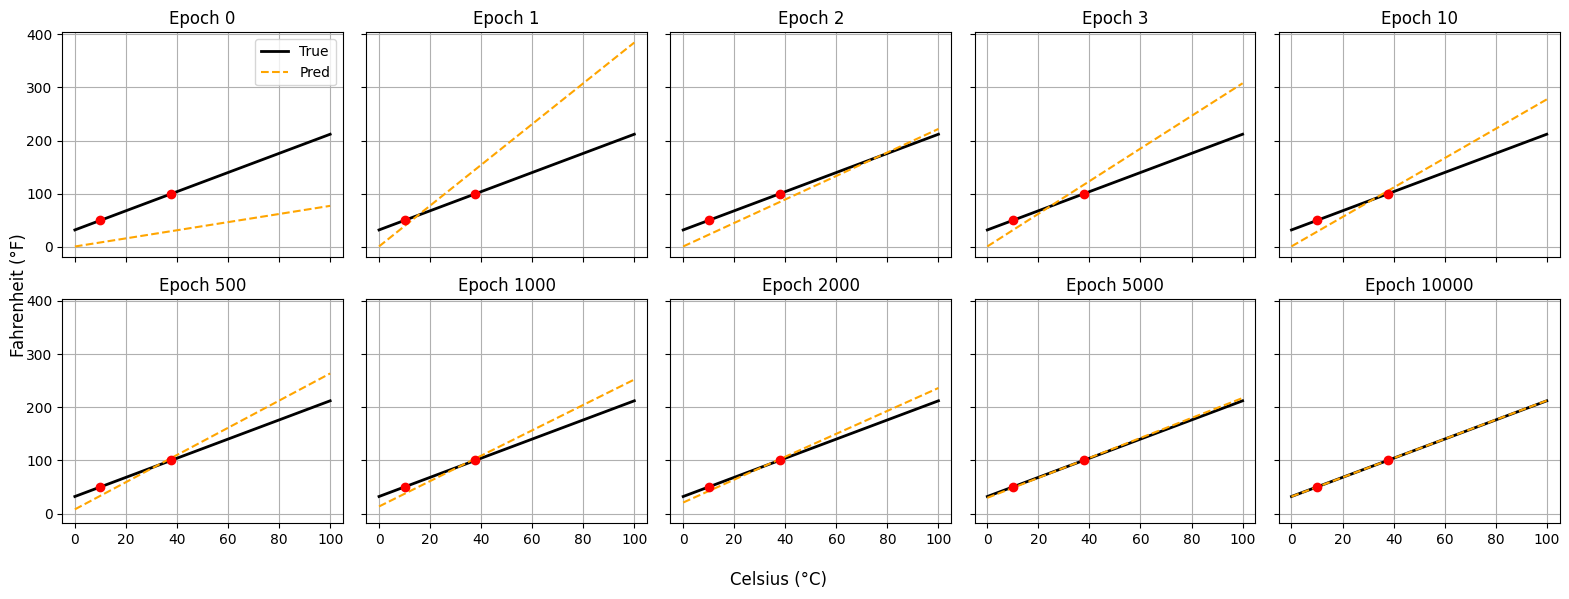

In [13]:
# 시각화용 섭씨 0~100도
celsius = np.linspace(0, 100, 51)
fahrenheit_true = celsius * 1.8 + 32

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True, sharey=True)
for ax, (epoch, w_s, b_s) in zip(axes.flatten(), snapshots):
    ax.plot(celsius, fahrenheit_true, color="black", linewidth=2, label="True")
    ax.plot(celsius, w_s * celsius + b_s, "--", color="orange", label="Pred")
    ax.scatter(X, y, color="red", zorder=3)
    ax.set_title(f"Epoch {epoch}")
    ax.grid(True)
axes[0, 0].legend()
fig.supxlabel("Celsius (°C)")
fig.supylabel("Fahrenheit (°F)")
plt.tight_layout()
plt.show()

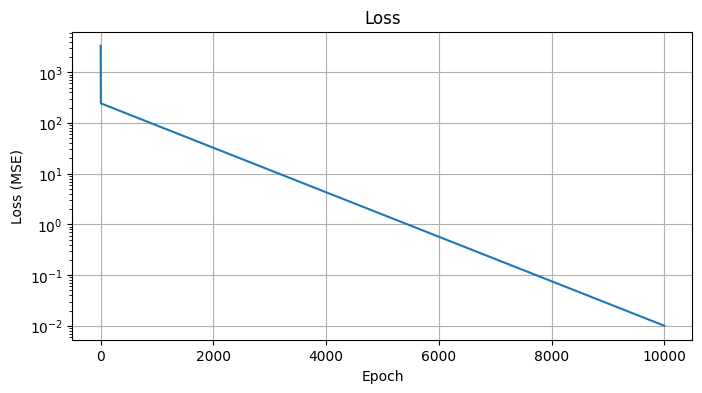

In [14]:
# 에폭별 손실 변화 (세로축은 로그 스케일)
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), losses)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Loss")
plt.grid(True)
plt.show()